# 📊 Análisis Exploratorio de Datos (EDA), Normalización y Estandarización con `pandas` y `matplotlib` — ACTHO 360

Este notebook desarrolla el **Análisis Exploratorio de Datos (EDA)** completo de los **47 archivos CSV** distribuidos en las dos carpetas (`CSV/` con 11 archivos y `Asistencia eventos/` con 36 archivos) utilizando **`pandas`** y **`matplotlib`**:

1. **Auditoría de Encabezados y Estructura de los 47 CSV ("Encabezados que no son")**: Clasificación de las 7 tipologías estructurales con `pandas` (`header=0`, `header=1`, `header=2`, `header=5`, `header=6` y archivos vacíos).
2. **Análisis de la Base Maestra `Afiliados.csv` (`pandas` + `matplotlib`)**: Auditoría de nulos, corrección de 580 celdas con mojibake, estados de membresía, sectores económicos y pilares estratégicos.
3. **Reconstrucción de los 5 Reportes Agrupados de Zoho CRM (`header=6` + `.ffill()`)**: `informe_membresias.csv`, `informe_por_segmentacion.csv`, `afiliaciones.csv`, `informe_renovaviones_ult_2_meses.csv` e `informe_subsectores.csv`.
4. **Análisis Integral de Asistencia a Eventos (`Asistencia eventos/`)**: Cruce de los 34 archivos individuales con `HOMOLOGACION OFERTA 2027.csv` y `GENERAL (2).csv`.
5. **Análisis de Gestión Comercial por KAM (`consolidado_asistencia.csv` y `estado.csv`)**.
6. **Análisis de Encuestas de Satisfacción (`EVENTO~1.XLS - Responses.csv` y `eventos_dos.csv`)**.
7. **Visualización de Todas las Tablas, Mapa de Cruces (`pd.merge` / `JOINs`) y Unificación en `fact_asistencias.csv`**.
8. **Normalización de 33 Campos Binarios a Booleanos (`True` / `False`) con `pandas`**.
9. **Normalización de 25 Columnas de Fecha y Timestamp a Estándar ISO-8601 (`YYYY-MM-DD`, `YYYY-MM`, `YYYY-MM-DD HH:MM:SS`)**.
10. **Estandarización de Datos Categóricos, Geográficos y Numéricos (`ciudad`, `region_departamento`, `pais`, `sector_economico`, `subsector_economico`, `rango_empleados`, `segmento_membresia`, `nivel_membresia`)**.
11. **Auditoría y Separación de los 122 Registros Duplicados en `normalizados/duplicados/`**.
12. **Vista Previa de las 7 Tablas Normalizadas y Ejemplo de `pd.merge` Relacional**.

---

## 🔍 1. Auditoría de Encabezados y Estructura de los 47 CSV ("Encabezados que no son")

Al inspeccionar los 47 archivos con `pandas`, comprobamos que **43 de los 47 archivos CSV (91.5%) NO tienen un encabezado tabular estándar en la Fila 0**:

| Tipología | Archivos | Parámetro `pandas.read_csv` | Diagnóstico Estructural |
| :--- | :---: | :---: | :--- |
| **Tipo A: Estándar** | **4** (`Afiliados.csv`, `consolidado_asistencia.csv`, `estado.csv`, `nuevos_afiliados.csv`) | `header=0` | Encabezado válido en Fila 0. `Afiliados.csv` tiene 580 celdas con mojibake (`Bogotﾃ｡`) y 12 columnas 100% nulas. |
| **Tipo B: Encuestas con Fila 0 vacía** | **2** (`EVENTO~1.XLS - Responses.csv`, `eventos_dos.csv`) | `header=1` | Fila 0 llena de comas vacías; encabezado real en Fila 1; Columna 0 sin nombre (`N_Respuesta`). |
| **Tipo C: Reportes Agrupados Zoho CRM** | **5** (`afiliaciones.csv`, `informe_membresias.csv`, `informe_por_segmentacion.csv`, `informe_renovaviones_ult_2_meses.csv`, `informe_subsectores.csv`) | `header=6` + `.ffill()` | Filas 0–5 son metadatos de exportación de Zoho CRM; celdas agrupadas en blanco y fila `Grand Total` al pie. |
| **Tipo D: Matriz Multi-encabezado** | **1** (`GENERAL (2).csv`) | `header=5` | Filas 1–4 contienen metadatos del evento (`MES`, `NÚMERO`, `FECHA`, `ACTIVIDAD`); Fila 581 contiene los totales. |
| **Tipo E: Catálogo con Título y Pie** | **1** (`HOMOLOGACION OFERTA 2027.csv`) | `header=2` | Fila 0 título, Fila 1 vacía, encabezado en Fila 2 y nota explicativa en Fila 38. |
| **Tipo F: Eventos Individuales** | **33** (`ENERO 5.csv` .. `OCTUBRE 27-2.csv`) | `header=1` | Fila 0 con título del evento (o saltos de línea `
` en `AGOSTO 18`/`19`, vacío en `MARZO 17`/`JULIO 29`, `"C"` en `ENERO 13`, `"MEDELLIN"` erróneo en `FEBRERO 10`); Col 0 y Col 7 sin nombre en Fila 1. |
| **Tipo G: Archivo Vacío** | **1** (`FEBRERO 13.csv`) | Archivo de 2 bytes (`""`) | Corresponde al Evento #6, sin encabezados ni filas de datos. |

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "CSV").exists():
    PROJECT_DIR = Path(r"d:\analisis_exploratorio")

BASE_DIR = PROJECT_DIR / "data" / "CSV"
ASIST_DIR = BASE_DIR / "Asistencia eventos"
NORM_DIR = PROJECT_DIR / "data" / "normalizados"
DUP_DIR = NORM_DIR / "duplicados"

try:
    from IPython.display import HTML, display
except ImportError:
    display = print
    HTML = str

if "mostrar_df" not in globals():
    def mostrar_df(df: pd.DataFrame, titulo: str = "", max_filas: int = 15) -> None:
        if titulo:
            display(HTML(f"<h4 style='color:#1e1b4b;margin:10px 0 4px 0;'>{titulo}</h4>"))
        display(df.head(max_filas))

def diagnosticar_csv_con_pandas(ruta: Path) -> dict:
    """Inspecciona un archivo CSV con pandas y clasifica su tipología de encabezado."""
    carpeta = "Asistencia eventos/" if ruta.parent.name == "Asistencia eventos" else "CSV/"
    nombre = ruta.name
    tamano = ruta.stat().st_size
    if tamano <= 5:
        return {
            "Carpeta": carpeta, "Archivo": nombre, "Bytes": tamano,
            "Filas_Brutas": 1, "Filas_Datos_Reales": 0, "Columnas": 0,
            "Parametro_Pandas": "Archivo vacío (<=5B)",
            "Tipologia": "Tipo G (Vacío)",
            "Diagnostico_Encabezado": "Archivo de 2 bytes ('""') sin encabezado ni registros",
        }

    df_raw = pd.read_csv(ruta, header=None, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    n_filas, n_cols = df_raw.shape

    zoho_files = {
        "afiliaciones.csv", "informe_membresias.csv", "informe_por_segmentacion.csv",
        "informe_renovaviones_ult_2_meses.csv", "informe_subsectores.csv",
    }
    if nombre in {"Afiliados.csv", "consolidado_asistencia.csv", "estado.csv", "nuevos_afiliados.csv"}:
        return {
            "Carpeta": carpeta, "Archivo": nombre, "Bytes": tamano,
            "Filas_Brutas": n_filas, "Filas_Datos_Reales": n_filas - 1, "Columnas": n_cols,
            "Parametro_Pandas": "header=0", "Tipologia": "Tipo A (Estándar)",
            "Diagnostico_Encabezado": "Encabezado en Fila 0 (Afiliados.csv tiene mojibake y 12 cols vacías)" if nombre == "Afiliados.csv" else "Encabezado estándar en Fila 0",
        }
    if nombre in {"EVENTO~1.XLS - Responses.csv", "eventos_dos.csv"}:
        return {
            "Carpeta": carpeta, "Archivo": nombre, "Bytes": tamano,
            "Filas_Brutas": n_filas, "Filas_Datos_Reales": n_filas - 2, "Columnas": n_cols,
            "Parametro_Pandas": "header=1", "Tipologia": "Tipo B (Encuesta)",
            "Diagnostico_Encabezado": "Fila 0 vacía; encabezado real en Fila 1; Col 0 sin nombre",
        }
    if nombre in zoho_files:
        return {
            "Carpeta": carpeta, "Archivo": nombre, "Bytes": tamano,
            "Filas_Brutas": n_filas, "Filas_Datos_Reales": max(0, n_filas - 9), "Columnas": n_cols,
            "Parametro_Pandas": "header=6", "Tipologia": "Tipo C (Reporte Zoho)",
            "Diagnostico_Encabezado": "Filas 0-5 metadatos Zoho CRM; celdas agrupadas vacías y Grand Total al final",
        }
    if nombre == "GENERAL (2).csv":
        return {
            "Carpeta": carpeta, "Archivo": nombre, "Bytes": tamano,
            "Filas_Brutas": n_filas, "Filas_Datos_Reales": n_filas - 7, "Columnas": n_cols,
            "Parametro_Pandas": "header=5", "Tipologia": "Tipo D (Matriz Anual)",
            "Diagnostico_Encabezado": "Filas 1-4 metadatos de eventos; Fila 5 encabezado; Fila 581 totales",
        }
    if nombre == "HOMOLOGACION OFERTA 2027.csv":
        return {
            "Carpeta": carpeta, "Archivo": nombre, "Bytes": tamano,
            "Filas_Brutas": n_filas, "Filas_Datos_Reales": 34, "Columnas": n_cols,
            "Parametro_Pandas": "header=2", "Tipologia": "Tipo E (Catálogo)",
            "Diagnostico_Encabezado": "Fila 0 título, Fila 1 vacía, Fila 2 encabezado y Fila 38 nota al pie",
        }

    # Archivos individuales de eventos (Tipo F)
    f0_vals = [v.strip() for v in df_raw.iloc[0].tolist() if v.strip()]
    f1_vals = [v.strip() for v in df_raw.iloc[1].tolist()]
    unnamed_pos = [i for i, v in enumerate(f1_vals) if v == ""]
    anomalias = []
    if not f0_vals:
        anomalias.append("Fila 0 vacía")
    elif f0_vals[0] == "C":
        anomalias.append("Título corrupto ('C') en Fila 0")
    elif "\n" in df_raw.iloc[0, 1] if n_cols > 1 else False:
        anomalias.append("Salto de línea (\n) incrustado en Fila 0")
    if nombre == "FEBRERO 10.csv":
        anomalias.append("Título dice MEDELLIN pero es Bogotá")
    if unnamed_pos:
        anomalias.append(f"Cols sin nombre en Fila 1: {unnamed_pos}")
    return {
        "Carpeta": carpeta, "Archivo": nombre, "Bytes": tamano,
        "Filas_Brutas": n_filas, "Filas_Datos_Reales": n_filas - 2, "Columnas": n_cols,
        "Parametro_Pandas": "header=1", "Tipologia": "Tipo F (Evento Individual)",
        "Diagnostico_Encabezado": "; ".join(anomalias),
    }

archivos_todos = sorted(BASE_DIR.glob("*.csv")) + sorted(ASIST_DIR.glob("*.csv"))
df_inventario = pd.DataFrame([diagnosticar_csv_con_pandas(p) for p in archivos_todos])

print(f"Total de archivos CSV auditados con pandas: {len(df_inventario)}")
print(df_inventario["Tipologia"].value_counts().to_string())
mostrar_df(df_inventario, "1.1 Inventario Completo y Diagnóstico de Encabezados de los 47 CSV (pandas)", max_filas=47)

Total de archivos CSV auditados con pandas: 47
Tipologia
Tipo F (Evento Individual)    33
Tipo C (Reporte Zoho)          5
Tipo A (Estándar)              4
Tipo B (Encuesta)              2
Tipo G (Vacío)                 1
Tipo D (Matriz Anual)          1
Tipo E (Catálogo)              1


Carpeta,Archivo,Bytes,Filas_Brutas,Filas_Datos_Reales,Columnas,Parametro_Pandas,Tipologia,Diagnostico_Encabezado
CSV/,afiliaciones.csv,1256,47,38,6,header=6,Tipo C (Reporte Zoho),Filas 0-5 metadatos Zoho CRM; celdas agrupadas vacías y Grand Total al final
CSV/,Afiliados.csv,250556,1074,1073,49,header=0,Tipo A (Estándar),Encabezado en Fila 0 (Afiliados.csv tiene mojibake y 12 cols vacías)
CSV/,consolidado_asistencia.csv,19204,462,461,7,header=0,Tipo A (Estándar),Encabezado estándar en Fila 0
CSV/,estado.csv,684,40,39,2,header=0,Tipo A (Estándar),Encabezado estándar en Fila 0
CSV/,eventos_dos.csv,71005,320,318,19,header=1,Tipo B (Encuesta),Fila 0 vacía; encabezado real en Fila 1; Col 0 sin nombre
CSV/,EVENTO~1.XLS - Responses.csv,80702,409,407,19,header=1,Tipo B (Encuesta),Fila 0 vacía; encabezado real en Fila 1; Col 0 sin nombre
CSV/,informe_membresias.csv,529,28,19,3,header=6,Tipo C (Reporte Zoho),Filas 0-5 metadatos Zoho CRM; celdas agrupadas vacías y Grand Total al final
CSV/,informe_por_segmentacion.csv,2856,96,87,4,header=6,Tipo C (Reporte Zoho),Filas 0-5 metadatos Zoho CRM; celdas agrupadas vacías y Grand Total al final
CSV/,informe_renovaviones_ult_2_meses.csv,929,32,23,5,header=6,Tipo C (Reporte Zoho),Filas 0-5 metadatos Zoho CRM; celdas agrupadas vacías y Grand Total al final
CSV/,informe_subsectores.csv,570,26,17,2,header=6,Tipo C (Reporte Zoho),Filas 0-5 metadatos Zoho CRM; celdas agrupadas vacías y Grand Total al final


---

## 🏢 2. Análisis de la Base Maestra de Empresas (`Afiliados.csv`) con `pandas` y `matplotlib`

Cargamos `Afiliados.csv` con `pd.read_csv`, auditamos sus **12 columnas 100% vacías**, corregimos las **580 celdas con mojibake** (`Bogotﾃ｡` → `Bogotá`, `Estﾃ｡ndar` → `Estándar`) y graficamos con `matplotlib` la distribución por estado de membresía, sector económico y pilares estratégicos:

Filas en Afiliados.csv: 1,073 | Columnas: 49 | Empresas únicas: 1,052
Columnas 100% vacías (13): ['Propietario de Empresa.id [eliminado]', 'Teléfono [eliminado]', 'Descripción [eliminado]', 'Hora de último enriquecimiento de datos', 'Estado de enriquecimiento de datos', 'Correo de facturación electrónica [eliminado]', 'Razón Social [eliminado]', 'Fecha Origen de la Compañía [eliminado]', 'Contacto principal [eliminado]', 'Nit [eliminado]', 'Correo electrónico Afiliado principal [eliminado]', 'Conexión Jurídico y Legal', 'Talento Aumentado']


Pilar Estratégico,Empresas con Registro,"% sobre Total (1,073)",Suma de Marcaciones
HR Estratégico,308,28.7%,322
Mas que un Salario,112,10.4%,154
Talento que Elige,103,9.6%,124
Conexión Jurídico y Legal,0,0.0%,0
Gente que Crece,66,6.2%,82
Talento Aumentado,0,0.0%,0


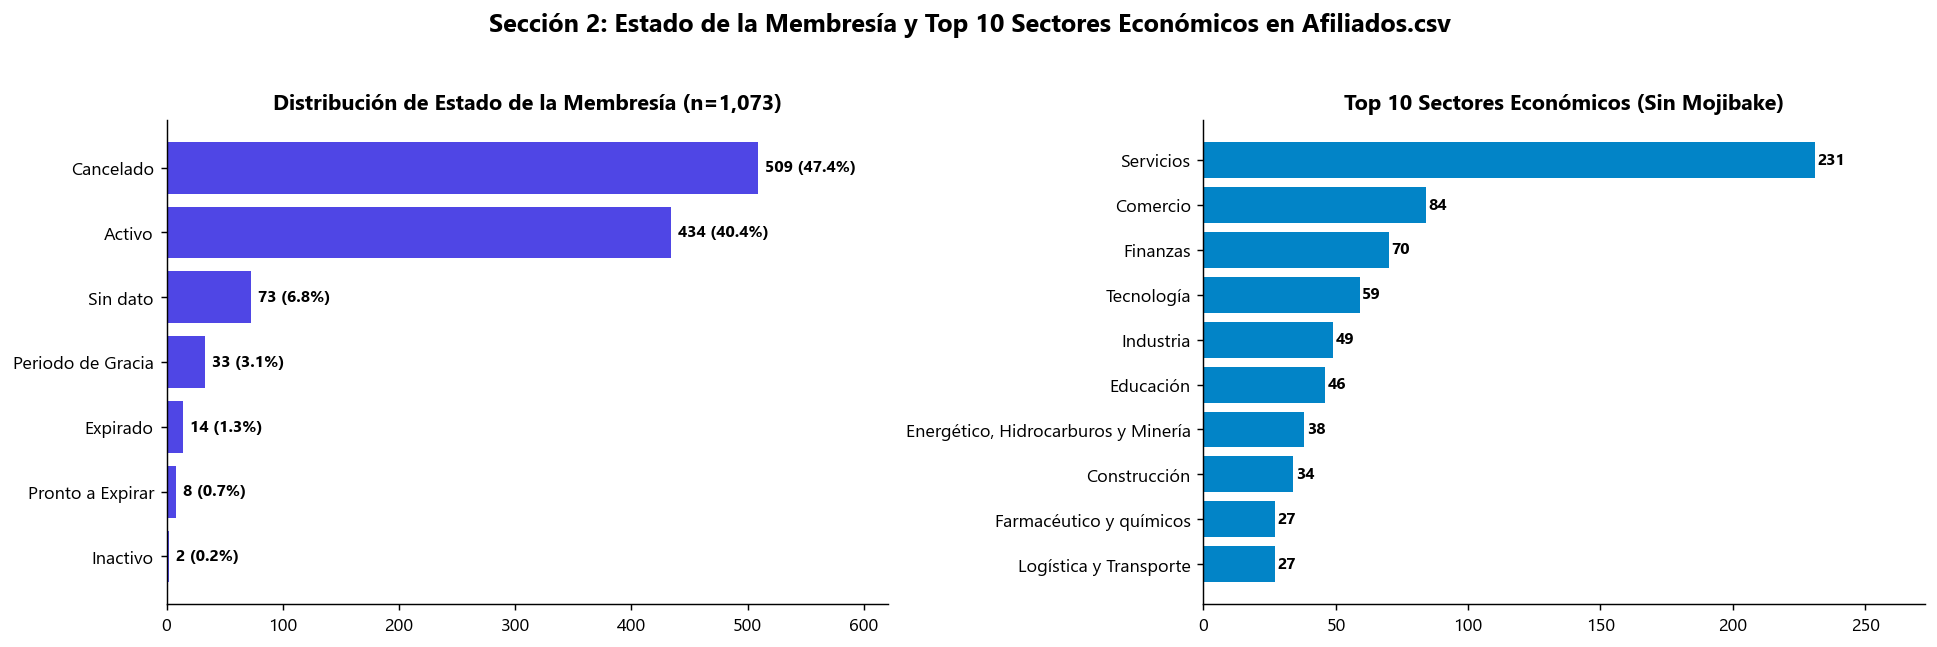

In [2]:
MOJIBAKE_MAP = {
    "ﾃ｡": "á", "ﾃｩ": "é", "ﾃｭ": "í", "ﾃｳ": "ó",
    "ﾃｻ": "ú", "ﾃｱ": "ñ", "ﾃｼ": "ü",
}

def limpiar_mojibake_serie(s: pd.Series) -> pd.Series:
    """Corrige secuencias mojibake y espacios en una Serie de texto de pandas."""
    res = s.astype(str)
    for k, v in MOJIBAKE_MAP.items():
        res = res.str.replace(k, v, regex=False)
    return res.str.strip().replace({"nan": np.nan, "": np.nan})

df_afiliados_raw = pd.read_csv(BASE_DIR / "Afiliados.csv")
cols_100_vacias = df_afiliados_raw.columns[df_afiliados_raw.isna().all()].tolist()
print(f"Filas en Afiliados.csv: {len(df_afiliados_raw):,} | Columnas: {df_afiliados_raw.shape[1]} | Empresas únicas: {df_afiliados_raw['Nombre de Empresa [anonimizado]'].nunique():,}")
print(f"Columnas 100% vacías ({len(cols_100_vacias)}): {cols_100_vacias}")

# Limpiar mojibake y unificar categorías en un DataFrame de pandas
df_af = df_afiliados_raw.copy()
for col_txt in ["Sector Económico", "Subsector Económico [anonimizado]", "Categoría de Membresía", "Tipo de Membresía", "Ciudad", "Región", "Departamento"]:
    df_af[col_txt] = limpiar_mojibake_serie(df_af[col_txt])

df_af["Categoría_Limpia"] = df_af["Categoría de Membresía"].replace({"Estandar": "Estándar"}).fillna("Sin dato")
df_af["Sector_Limpio"] = df_af["Sector Económico"].replace({"Tecnologia": "Tecnología"}).fillna("Sin dato")

# Tabla de Pilares Estratégicos con pandas
pilares_cols = ["HR Estratégico", "Mas que un Salario", "Talento que Elige", "Conexión Jurídico y Legal", "Gente que Crece", "Talento Aumentado"]
df_pilares = pd.DataFrame([
    {
        "Pilar Estratégico": col,
        "Empresas con Registro": int(df_af[col].notna().sum()),
        "% sobre Total (1,073)": f"{df_af[col].notna().mean()*100:.1f}%",
        "Suma de Marcaciones": int(pd.to_numeric(df_af[col], errors="coerce").fillna(0).sum()),
    }
    for col in pilares_cols
])
mostrar_df(df_pilares, "2.1 Adopción de Pilares Estratégicos en Afiliados.csv (pandas)")

# Gráficos con Matplotlib
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
fig.suptitle("Sección 2: Estado de la Membresía y Top 10 Sectores Económicos en Afiliados.csv", fontsize=14, fontweight="bold", y=1.03)

est_mem = df_af["Estado de la Membresía"].fillna("Sin dato").value_counts().sort_values(ascending=True)
axes[0].barh(est_mem.index, est_mem.values, color="#4f46e5")
for i, v in enumerate(est_mem.values):
    axes[0].text(v + 6, i, f"{v} ({v*100/len(df_af):.1f}%)", va="center", fontweight="bold", fontsize=9)
axes[0].set_title("Distribución de Estado de la Membresía (n=1,073)", fontweight="bold")
axes[0].set_xlim(0, est_mem.max() * 1.22)

top_sec = df_af[df_af["Sector_Limpio"] != "Sin dato"]["Sector_Limpio"].value_counts().head(10).sort_values(ascending=True)
axes[1].barh(top_sec.index, top_sec.values, color="#0284c7")
for i, v in enumerate(top_sec.values):
    axes[1].text(v + 1, i, str(v), va="center", fontweight="bold", fontsize=9)
axes[1].set_title("Top 10 Sectores Económicos (Sin Mojibake)", fontweight="bold")
axes[1].set_xlim(0, top_sec.max() * 1.18)

plt.tight_layout()
plt.show()

---

## 📋 3. Reconstrucción de los 5 Reportes Agrupados de Zoho CRM con `pandas` (`header=6` + `.ffill()`)

Utilizamos `pd.read_csv(..., skiprows=6)` y `.ffill()` sobre las columnas de agrupación jerárquica para reconstruir como `DataFrame` limpios los 5 reportes exportados de Zoho CRM:

In [3]:
def leer_reporte_zoho_pandas(ruta: Path, cols_grupo: list[int]) -> pd.DataFrame:
    """Lee un reporte agrupado de Zoho CRM saltando las 6 filas de metadatos y aplicando ffill."""
    df = pd.read_csv(ruta, skiprows=6, dtype=str, keep_default_na=True, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    df = df.dropna(how="all")
    primera_col = df.columns[0]
    df = df[df[primera_col].astype(str).str.strip() != "Grand Total"].copy()
    if ruta.name == "informe_membresias.csv":
        df = df[~(df.iloc[:, 0].isna() & df.iloc[:, 1].isna())].copy()
    for col in df.columns:
        df[col] = limpiar_mojibake_serie(df[col])
    for idx in cols_grupo:
        col_name = df.columns[idx]
        df[col_name] = df[col_name].str.replace(r"\s*\(\s*\d+\s*\)\s*$", "", regex=True).str.strip()
        df[col_name] = df[col_name].ffill()
    return df.reset_index(drop=True)

df_zoho_memb = leer_reporte_zoho_pandas(BASE_DIR / "informe_membresias.csv", [0])
df_zoho_segm = leer_reporte_zoho_pandas(BASE_DIR / "informe_por_segmentacion.csv", [0, 1])
df_zoho_afil = leer_reporte_zoho_pandas(BASE_DIR / "afiliaciones.csv", [0, 1, 2])
df_zoho_reno = leer_reporte_zoho_pandas(BASE_DIR / "informe_renovaviones_ult_2_meses.csv", [0, 1])
df_zoho_subs = leer_reporte_zoho_pandas(BASE_DIR / "informe_subsectores.csv", [])

print(f"informe_membresias.csv: {len(df_zoho_memb)} filas | Suma Cantidad de registros: {pd.to_numeric(df_zoho_memb['Cantidad de registros']).sum()}")
print(f"informe_por_segmentacion.csv: {len(df_zoho_segm)} cuentas Elite/Premium")
print(f"afiliaciones.csv: {len(df_zoho_afil)} nuevas afiliaciones | informe_renovaviones_ult_2_meses.csv: {len(df_zoho_reno)} renovaciones")

mostrar_df(df_zoho_memb, "3.1 Tabla Reconstruida con pandas: informe_membresias.csv (481 Membresías Activas)")
mostrar_df(df_zoho_afil, "3.2 Tabla Reconstruida con pandas: afiliaciones.csv (14 Afiliaciones Recientes)")
mostrar_df(df_zoho_reno, "3.3 Tabla Reconstruida con pandas: informe_renovaviones_ult_2_meses.csv (14 Renovaciones)")

informe_membresias.csv: 14 filas | Suma Cantidad de registros: 481
informe_por_segmentacion.csv: 89 cuentas Elite/Premium
afiliaciones.csv: 14 nuevas afiliaciones | informe_renovaviones_ult_2_meses.csv: 14 renovaciones


Tipo de Membresía,Categoría de Membresía,Cantidad de registros
Empresa,Elite,5
Empresa,Premium,74
Empresa,Estándar,245
Empresa,Estandar,18
Consultoras,Premium,10
Consultoras,Estándar,90
Consultoras,Estandar,11
Persona Natural,Premium,2
Persona Natural,Estándar,8
Persona Natural,Personal,4


---

## 📅 4, 5 y 6. Análisis de Asistencia a Eventos, Gestión KAM y Encuestas de Satisfacción con `pandas` y `matplotlib`

Analizamos las tablas consolidadas de eventos (`dim_eventos.csv` y `fact_asistencias.csv`), el seguimiento por portafolio KAM (`consolidado_asistencia.csv`) y las encuestas de satisfacción presenciales y virtuales (`fact_encuestas_satisfaccion.csv`):

Total participaciones en fact_asistencias.csv: 3,401
Personas únicas asistentes: 2,573 | Empresas únicas asistentes: 1,197


id_evento,archivo_csv,fecha_evento,nombre_evento,linea_oferta_2027,modalidad,total_asistentes_archivo,empresas_unicas_archivo,total_reportado_matriz_general
1,ENERO 5.csv,2026-01-05,"Webinar: Salario mínimo 2026 en Colombia: preguntas, retos y decisiones clave",Anticipar,Virtual,511,381,123
2,ENERO 13.csv,2026-01-13,Webinar: Equilibrio entre personas y negocios. Conversaciones sobre salario mínimo 2026,Anticipar,Virtual,351,274,87
3,FEBRERO 4.csv,2026-02-04,Foro híbrido de tendencias,Evento grande,Híbrido,54,44,30
4,FEBRERO 10.csv,2026-02-10,Sesiones de trabajo de proyecciones salariales: ajuste salarial 2026 (Bogotá),Anticipar,Presencial,30,19,16
5,FEBRERO 12.csv,2026-02-12,Sesiones de trabajo de proyecciones salariales: ajuste salarial 2026 (Medellín),Anticipar,Presencial,17,12,9
6,FEBRERO 13.csv,2026-02-13,Live: Suspensión al alza del salario mínimo 2026,Anticipar,Virtual,0,0,0
7,MARZO 17.csv,2026-03-17,Semana del Talento (17 al 20 de marzo),Evento grande,Presencial,532,257,182
8,MARZO 25.csv,2026-03-25,Webinar Decreto 0234 de 2026: cambios en la negociación colectiva,Anticipar,Virtual,94,63,22
9,ABRIL 16.csv,2026-04-16,Webinar: Tolerancia cero: cómo prevenir y gestionar el acoso sexual en el trabajo,Anticipar,Virtual,326,179,62
10,ABRIL 28.csv,2026-04-28,Taller: Gestión del acoso sexual en las organizaciones (Bogotá),Anticipar,Presencial,37,30,29


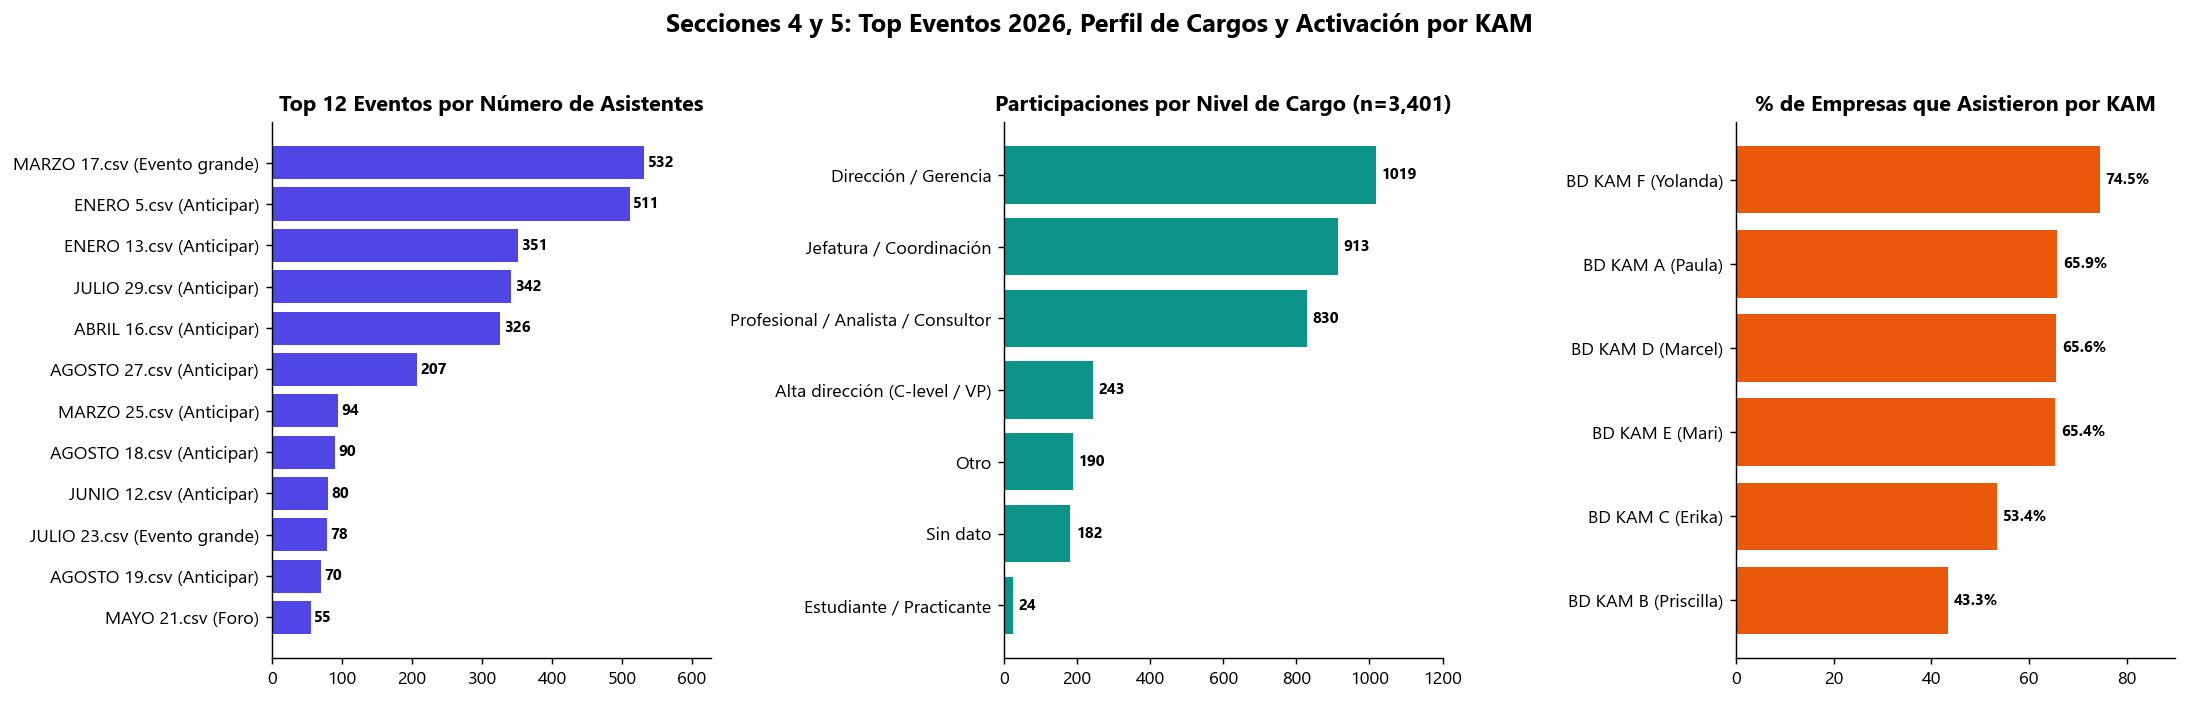

In [4]:
dim_eventos_df = pd.read_csv(NORM_DIR / "dim_eventos.csv")
fact_asist_df = pd.read_csv(NORM_DIR / "fact_asistencias.csv")
df_cons_kam = pd.read_csv(BASE_DIR / "consolidado_asistencia.csv")
fact_enc_df = pd.read_csv(NORM_DIR / "fact_encuestas_satisfaccion.csv")

print(f"Total participaciones en fact_asistencias.csv: {len(fact_asist_df):,}")
print(f"Personas únicas asistentes: {fact_asist_df['id_persona'].nunique():,} | Empresas únicas asistentes: {fact_asist_df['id_empresa'].nunique():,}")

# Resumen por KAM desde consolidado_asistencia.csv con pandas.groupby
resumen_kam_df = (
    df_cons_kam.groupby(["BD_KAM", "Responsable"], as_index=False)
    .agg(
        Total_Empresas=("Empresa", "count"),
        Asistieron=("Estado_Asistencia", lambda s: (s == "Asistió").sum()),
        No_Asistieron=("Estado_Asistencia", lambda s: (s != "Asistió").sum()),
        Eventos_Asistidos=("Eventos_Asistidos", "sum"),
        Total_Asistentes=("Total_Asistentes", "sum"),
    )
)
resumen_kam_df["% Activación"] = (resumen_kam_df["Asistieron"] * 100 / resumen_kam_df["Total_Empresas"]).round(1).astype(str) + "%"
resumen_kam_df["Prom_Eventos_Empresa"] = (resumen_kam_df["Eventos_Asistidos"] / resumen_kam_df["Total_Empresas"]).round(2)

mostrar_df(
    dim_eventos_df[["id_evento", "archivo_csv", "fecha_evento", "nombre_evento", "linea_oferta_2027", "modalidad", "total_asistentes_archivo", "empresas_unicas_archivo", "total_reportado_matriz_general"]],
    "4.1 Catálogo Consolidado de los 34 Eventos 2026: Archivos Individuales vs Matriz GENERAL (2)",
    max_filas=34,
)
mostrar_df(resumen_kam_df, "5.1 Desempeño de Participación por Portafolio KAM (consolidado_asistencia.csv con pandas)")

# Gráficos con Matplotlib (Top 12 Eventos, Nivel de Cargo y Activación KAM)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
fig.suptitle("Secciones 4 y 5: Top Eventos 2026, Perfil de Cargos y Activación por KAM", fontsize=14, fontweight="bold", y=1.03)

top12_ev = dim_eventos_df.sort_values("total_asistentes_archivo", ascending=True).tail(12)
axes[0].barh(top12_ev["archivo_csv"] + " (" + top12_ev["linea_oferta_2027"] + ")", top12_ev["total_asistentes_archivo"], color="#4f46e5")
for i, v in enumerate(top12_ev["total_asistentes_archivo"]):
    axes[0].text(v + 5, i, str(v), va="center", fontweight="bold", fontsize=8.5)
axes[0].set_title("Top 12 Eventos por Número de Asistentes", fontweight="bold")
axes[0].set_xlim(0, top12_ev["total_asistentes_archivo"].max() * 1.18)

cargos_cnt = fact_asist_df["nivel_cargo"].value_counts().sort_values(ascending=True)
axes[1].barh(cargos_cnt.index, cargos_cnt.values, color="#0d9488")
for i, v in enumerate(cargos_cnt.values):
    axes[1].text(v + 15, i, str(v), va="center", fontweight="bold", fontsize=8.5)
axes[1].set_title("Participaciones por Nivel de Cargo (n=3,401)", fontweight="bold")
axes[1].set_xlim(0, cargos_cnt.max() * 1.18)

kam_pct = (resumen_kam_df["Asistieron"] * 100 / resumen_kam_df["Total_Empresas"]).values
kam_lbl = (resumen_kam_df["BD_KAM"] + " (" + resumen_kam_df["Responsable"] + ")").values
orden_k = np.argsort(kam_pct)
axes[2].barh(kam_lbl[orden_k], kam_pct[orden_k], color="#ea580c")
for i, v in enumerate(kam_pct[orden_k]):
    axes[2].text(v + 1.2, i, f"{v:.1f}%", va="center", fontweight="bold", fontsize=8.5)
axes[2].set_title("% de Empresas que Asistieron por KAM", fontweight="bold")
axes[2].set_xlim(0, 90)

plt.tight_layout()
plt.show()

---

## 🧹 7 a 12. Auditoría con `pandas` de Campos Booleanos, Fechas ISO-8601, Categorías Estandarizadas y los 122 Duplicados

Verificamos mediante `pandas` sobre las **7 tablas normalizadas** (`data/normalizados/`) y la carpeta `data/normalizados/duplicados/`:
1. **33 columnas booleanas (`bool`)** estandarizadas (`True` / `False`).
2. **25 columnas de fecha/timestamp** en formato **ISO-8601** (`0` valores fuera de norma).
3. **Estandarización geográfica y comercial** (`56` ciudades canónicas, `13` regiones, `6` rangos de empleados, `segmento_membresia` y `nivel_membresia`).
4. **122 registros duplicados** documentados en `normalizados/duplicados/` mientras las tablas principales conservan el 100% de sus filas:

In [5]:
tablas_norm_nombres = [
    "dim_empresas.csv", "dim_eventos.csv", "dim_kams.csv", "dim_personas.csv",
    "fact_asistencias.csv", "fact_encuestas_satisfaccion.csv", "fact_movimientos_crm.csv",
]
dfs_norm = {fn: pd.read_csv(NORM_DIR / fn) for fn in tablas_norm_nombres}

# 1. Auditoría de las 33 columnas booleanas con pandas
bool_rows = []
for fn, df_n in dfs_norm.items():
    for col in df_n.columns:
        if df_n[col].dtype == bool or set(df_n[col].dropna().astype(str).unique()).issubset({"True", "False"}):
            s_bool = df_n[col].astype(str) == "True"
            t_cnt = int(s_bool.sum())
            f_cnt = int((~s_bool).sum())
            bool_rows.append({
                "Tabla Normalizada": fn,
                "Columna Booleana": col,
                "Conteo True": t_cnt,
                "Conteo False": f_cnt,
                "% True": f"{t_cnt * 100 / len(df_n):.1f}%",
            })
df_bool_audit = pd.DataFrame(bool_rows)
print(f"Total columnas booleanas verificadas con pandas: {len(df_bool_audit)}")
mostrar_df(df_bool_audit, "9.1 Catálogo de las 33 Columnas Booleanas (True / False) Auditadas con pandas", max_filas=35)

# 2. Auditoría de las 25 columnas de fecha/timestamp ISO-8601 con pandas
patron_iso = re.compile(r"^(\d{4}-\d{2}-\d{2}|\d{4}-\d{2}|\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})$")
fecha_rows = []
for fn, df_n in dfs_norm.items():
    for col in df_n.columns:
        if "fecha" in col or "periodo_mes" in col:
            s_val = df_n[col].dropna().astype(str)
            invalidos = int((~s_val.str.match(patron_iso)).sum())
            fecha_rows.append({
                "Tabla Normalizada": fn,
                "Columna Fecha / Timestamp": col,
                "Registros con Fecha": len(s_val),
                "Fuera de Norma ISO": invalidos,
                "Mínimo ISO": s_val.min() if len(s_val) else "-",
                "Máximo ISO": s_val.max() if len(s_val) else "-",
            })
df_fecha_audit = pd.DataFrame(fecha_rows)
print(f"Total columnas de fecha/timestamp ISO-8601: {len(df_fecha_audit)} | Total fuera de norma: {df_fecha_audit['Fuera de Norma ISO'].sum()}")
mostrar_df(df_fecha_audit, "10.1 Auditoría de las 25 Columnas de Fecha y Timestamp en Estándar ISO-8601", max_filas=25)

# 3. Resumen de archivos en normalizados/duplicados/ con pandas
archivos_dups = [
    "registros_duplicados.csv",
    "duplicados_asistencias_eventos.csv",
    "duplicados_afiliados_crm.csv",
    "duplicados_matriz_general_y_kam.csv",
    "duplicados_movimientos_crm.csv",
    "duplicados_encuestas_satisfaccion.csv",
]
df_dups_resumen = pd.DataFrame([
    {
        "Archivo en normalizados/duplicados/": fn,
        "Registros Duplicados": len(pd.read_csv(DUP_DIR / fn)),
        "Columnas": pd.read_csv(DUP_DIR / fn).shape[1],
    }
    for fn in archivos_dups
])
mostrar_df(df_dups_resumen, "12.1 Archivos CSV de Duplicados en data/normalizados/duplicados/")

Total columnas booleanas verificadas con pandas: 33
Total columnas de fecha/timestamp ISO-8601: 25 | Total fuera de norma: 0


Tabla Normalizada,Columna Booleana,Conteo True,Conteo False,% True
dim_empresas.csv,es_empresa_activa,481,1370,26.0%
dim_empresas.csv,es_membresia_activa,433,1418,23.4%
dim_empresas.csv,es_independiente,41,1810,2.2%
dim_empresas.csv,es_registro_prueba,2,1849,0.1%
dim_empresas.csv,bloqueado_crm,0,1851,0.0%
dim_empresas.csv,vinculado_comunidades,339,1512,18.3%
dim_empresas.csv,pilar_hr_estrategico,294,1557,15.9%
dim_empresas.csv,pilar_mas_que_salario,93,1758,5.0%
dim_empresas.csv,pilar_talento_que_elige,90,1761,4.9%
dim_empresas.csv,pilar_gente_que_crece,58,1793,3.1%


---

## ✨ 13. Vista Previa de las 7 Tablas Normalizadas y Cruce Relacional con `pandas.merge`

Mostramos con `pandas` cada una de las 7 tablas normalizadas y ejecutamos un `pd.merge` relacional uniendo `fact_asistencias` con `dim_eventos`, `dim_empresas` y `dim_kams`:

In [6]:
for fn in tablas_norm_nombres:
    mostrar_df(dfs_norm[fn], f"Vista Previa con pandas: {fn}", max_filas=6)

# Ejemplo de JOIN relacional con pd.merge
df_join_relacional = (
    dfs_norm["fact_asistencias.csv"]
    .merge(dfs_norm["dim_eventos.csv"][["id_evento", "nombre_evento", "linea_oferta_2027", "modalidad"]], on="id_evento", how="left")
    .merge(dfs_norm["dim_empresas.csv"][["id_empresa", "es_membresia_activa", "segmento_membresia", "nivel_membresia", "sector_economico", "ciudad"]], on="id_empresa", how="left")
    .merge(dfs_norm["dim_kams.csv"][["kam_id", "responsable_nombre"]], on="kam_id", how="left")
)

cols_mostrar_join = [
    "id_asistencia", "fecha_evento", "nombre_evento", "linea_oferta_2027", "modalidad",
    "id_empresa", "es_membresia_activa", "segmento_membresia", "nivel_membresia",
    "responsable_nombre", "id_persona", "nivel_cargo", "es_afiliado", "autoriza_tratamiento_datos",
]
print(f"Total filas en el cruce relacional (pd.merge): {len(df_join_relacional):,}")
mostrar_df(df_join_relacional[cols_mostrar_join], "13.1 Resultado del JOIN Relacional con pandas.merge (fact_asistencias ⋈ dim_eventos ⋈ dim_empresas ⋈ dim_kams)", max_filas=12)

Total filas en el cruce relacional (pd.merge): 3,401
